In [ ]:
# Path setup: lets the notebook run from anywhere inside the repo
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir() and (p / "src").is_dir())
DATA = ROOT / "data"
sys.path[:0] = [str(ROOT / "src"), str(ROOT / "supervisor_code")]

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from time import time
from tqdm import tqdm
import math as math
import statsmodels.tsa as sm
from sklearn.linear_model import LinearRegression,Lasso,Ridge
from scipy.stats import t, laplace, uniform,norm
from scipy.optimize import minimize
from collections import defaultdict
import pickle
from copy import copy
import warnings
import os,sys,psutil
%load_ext autoreload
%autoreload 2

/var/folders/qm/p0xj4dzj0_n_c5vnqnwwwdgc0000gn/T/ipykernel_37905/4052563241.py:1: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


In [2]:
from classes import *
from functions_univariate import *
#from utils import *

### Storing Results : convergence of the algorithm
On lance $p$ fois l'algorithme, à chaque fois on regénère des données au préalable (sinon tout est déterministe)

In [55]:
sample_size = 4000
true_params =  {'alpha':np.array([[0.2,0.8]]),\
                'P': np.array([[0.8,0.2],[0.1,0.9]]),\
                'omega':np.array([0.2,0.8]),\
                #'exogen_transition' : np.random.uniform(0,1,size=(sample_size)),\
                'beta' : np.array([[-0.1,0.1],[0.5,-0.5]]),\
                #'mu' : np.array([1,0.1]),\
                #'exogen_additive' : abs(AR([0.9,0.08],length=sample_size*2)).reshape(sample_size,2),\
                'exogen_transition' : AR([0.9,0.08],length=sample_size),\
                'transition_f' : 'soft-exp',\
                #'seed' : 3,\
                    }

initial_params =    {'pi_0' : np.array([0.5,0.5]),\
                    'omega' : np.array([0.5,0.5]),\
                    'P' : np.ones((2,2))/2,\
                    'alpha' : np.array([[0,0]]),\
                    #'exogen_additive' : (true_params.get('exogen_additive',None)),\
                    'exogen_transition' : (true_params.get('exogen_transition',None)),\
                    'transition_f' : 'soft-exp',\
                    #'beta' : np.array([0,1]),\
                    'beta' : np.array([[0,0],[0,0]]),\
                    'beta_constraint' : 'general'
                    #'mu' : np.array([0.5,0.5]),\
                    }



niter = 400
p = 100


def run_simulation(true_params, initial_params, sample_size, niter):
    model = MS_ARCH(true_params=true_params)
    model.simulate(length=sample_size)
    results = MS_EM_algorithm(model.eps,initial_params,niter)
    return results

In [56]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for batch in range(1,11):
        for sample_size in [500,1000,2000,4000]:
            store_results = {}
            p = 300
            for i in tqdm(range(p)):
                store_results[i+1] = run_simulation(true_params.copy(), initial_params.copy(), sample_size, niter)
                del store_results[i+1][0]['exogen_transition']
            store_results['true_params'] = true_params
            with open(f"Results//results_{sample_size}_batch{batch}"+".pkl", "wb") as f:
                pickle.dump(store_results, f)

100%|██████████| 400/400 [00:09<00:00, 41.90it/s]] 
100%|██████████| 400/400 [02:36<00:00,  2.
[... output truncated ...]
00/400 [00:16<00:00, 24.13it/s]]
 36%|███▌      | 107/300 [1:28:27<1:32:20, 28.71s/it]Exception ignored in: <bound method IPythonKernel._clean_thread_parent_frames of <ipykernel.ipkernel.IPythonKernel object at 0x1058b7b30>>
Traceback (most recent call last):
  File "/Users/raphaelthabut/Library/Python/3.12/lib/python/site-packages/ipykernel/ipkernel.py", line 770, in _clean_thread_parent_frames
    def _clean_thread_parent_frames(

KeyboardInterrupt: 


## Convergence numérique asymptotique

In [3]:
with open(f"Results//results_4000"+".pkl", "rb") as f:
    Results = pickle.load(f)

In [53]:
import sys

def deep_getsizeof(obj, seen=None):
    """
    Recursively calculate the memory size of a nested object.
    """
    if seen is None:
        seen = set()
    obj_id = id(obj)
    if obj_id in seen:
        return 0  # Avoid double-counting circular references
    seen.add(obj_id)
    size = sys.getsizeof(obj)
    if isinstance(obj, dict):
        size += sum(deep_getsizeof(v, seen) for v in obj.values())
        size += sum(deep_getsizeof(k, seen) for k in obj.keys())
    elif isinstance(obj, (list, tuple, set)):
        size += sum(deep_getsizeof(i, seen) for i in obj)
    return size
# Calculate memory size
total_memory = deep_getsizeof(Results)
print(f"Total memory size of the nested dictionary: {total_memory/10**6} Mo")


Total memory size of the nested dictionary: 35.028903 Mo


In [124]:
columns = ['P','beta','omega','alpha','pi_0','log-likelihood']
Dfs = []
for i in tqdm(Results.keys()):
    if i != 'true_params':
        Results[i][0] = {key:value for key,value in Results[i][0].items() if key not in ['exogen_transition','mu_depends_on_delta','exogen_additive','transition_f','beta_constraint']}
        new_df = convert_dict_to_dataframe(Results[i])
        new_df['version'] = i
        Dfs.append(new_df)
df = pd.concat(Dfs)
true_values = convert_dict_to_dataframe({0:{key:value for key,value in true_params.items() if key not in ['exogen_transition','mu_depends_on_delta','exogen_additive','transition_f']}})

  0%|          | 0/101 [00:00<?, ?it/s]

100%|██████████| 101/101 [00:14<00:00,  6.87it/s]


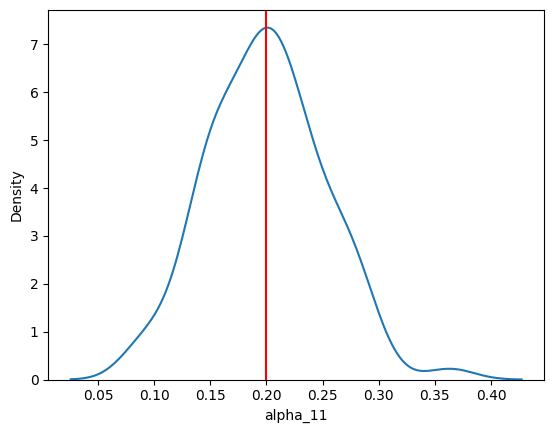

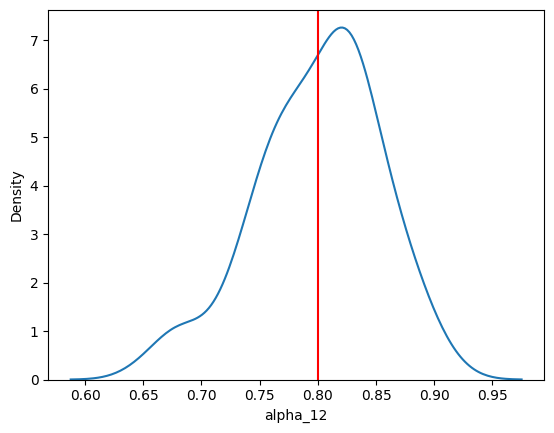

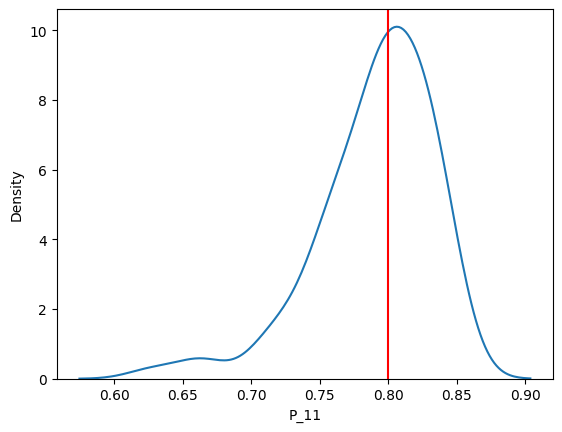

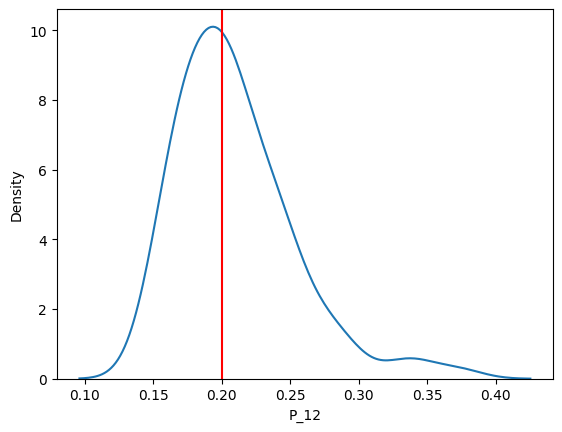

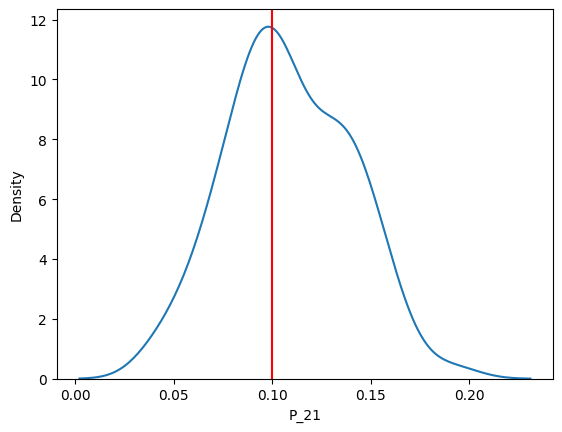

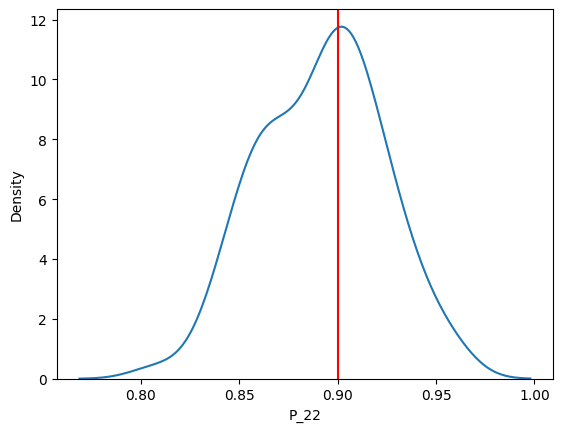

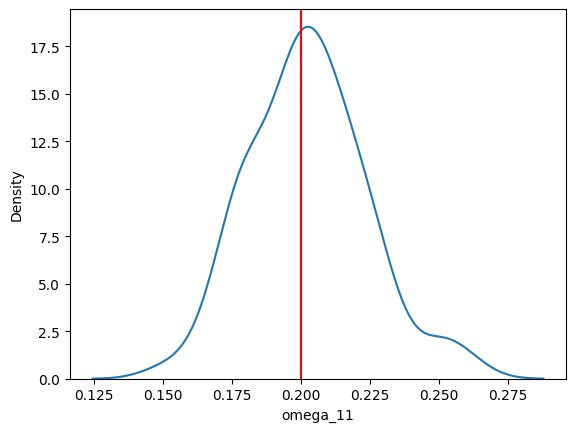

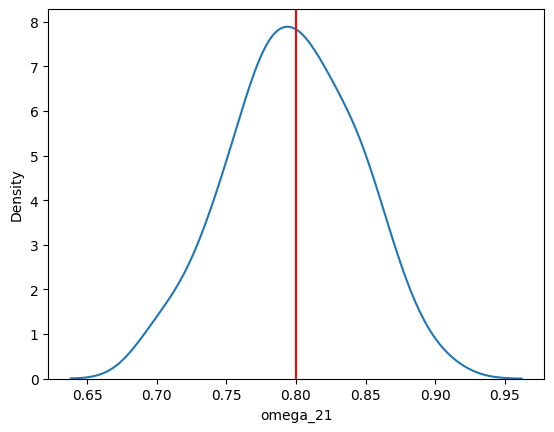

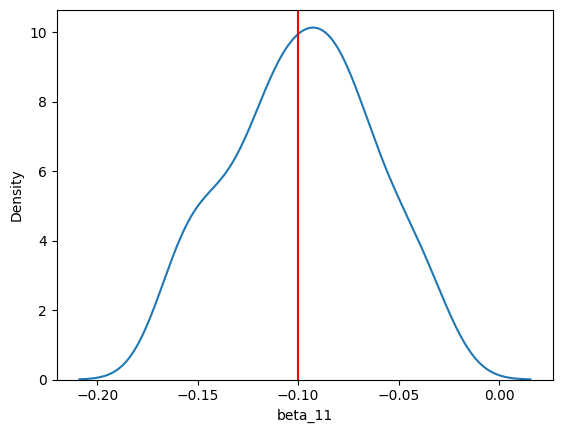

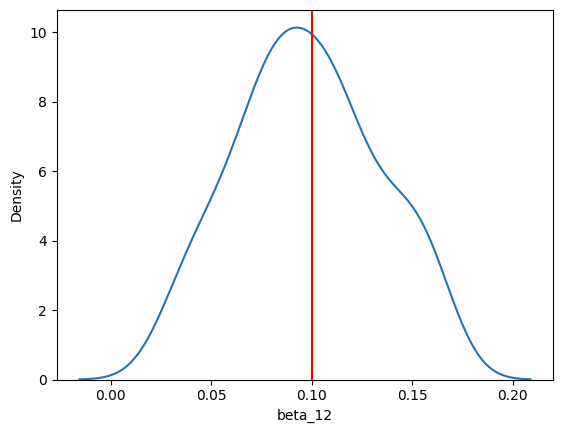

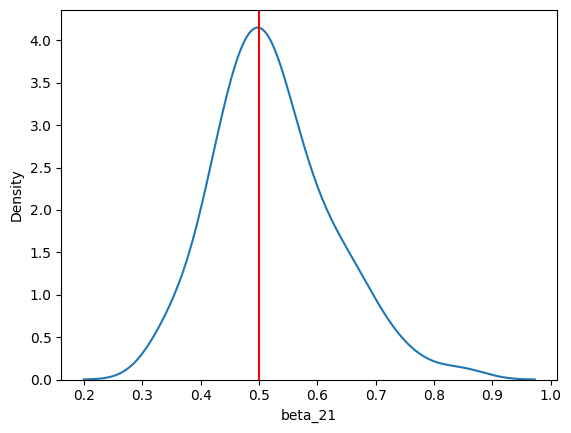

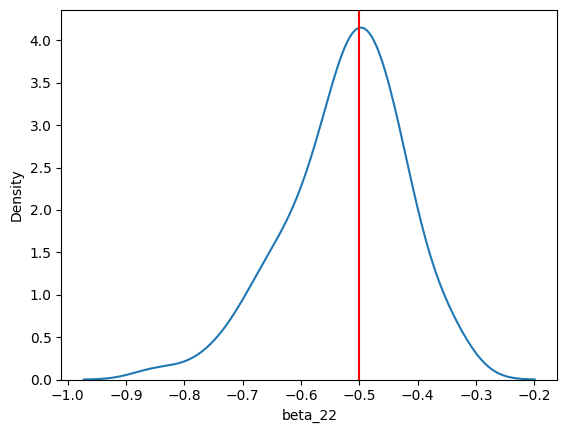

In [125]:
for col in true_values.columns:
    df[col+' error'] = true_values[col].squeeze() - df[col]
    sns.kdeplot(df.loc[299].dropna(axis=0),x=col)
    plt.axvline(true_values[col].squeeze(),color='red')
    plt.show()

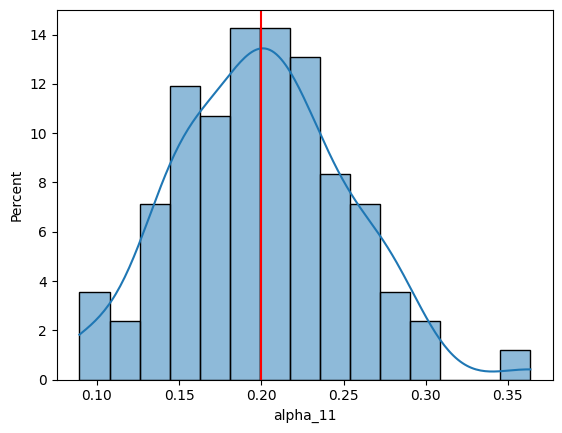

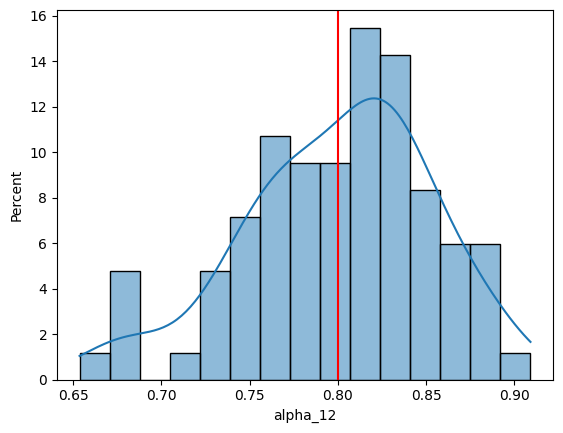

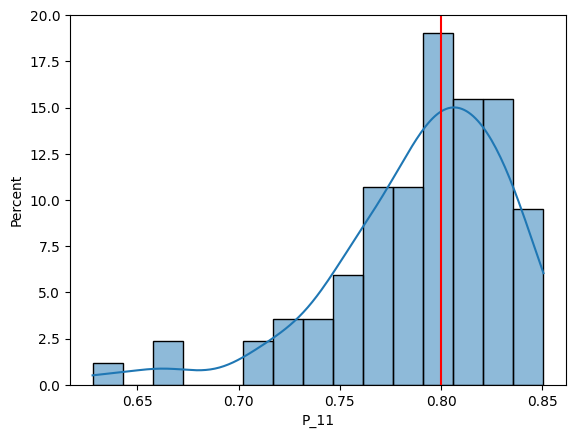

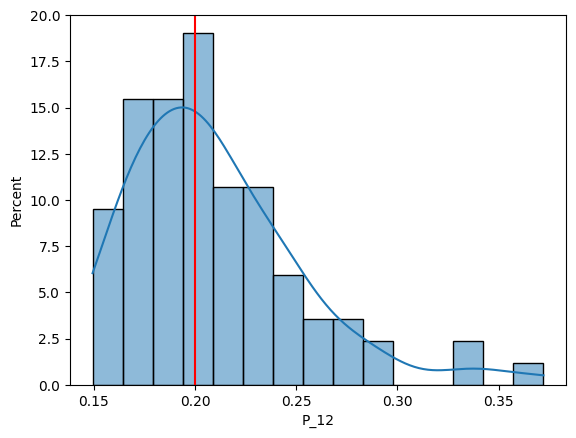

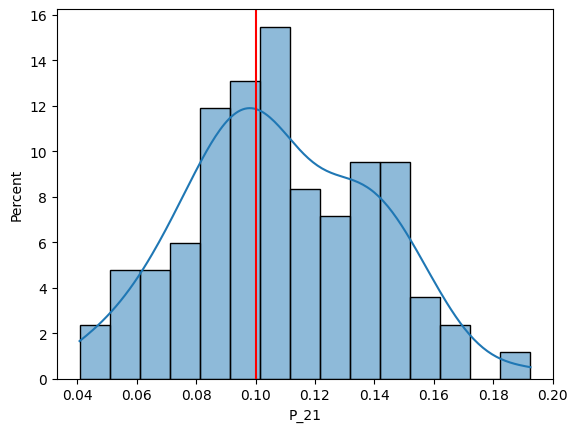

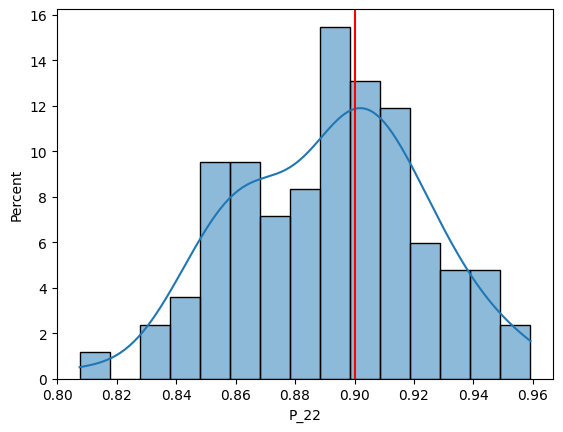

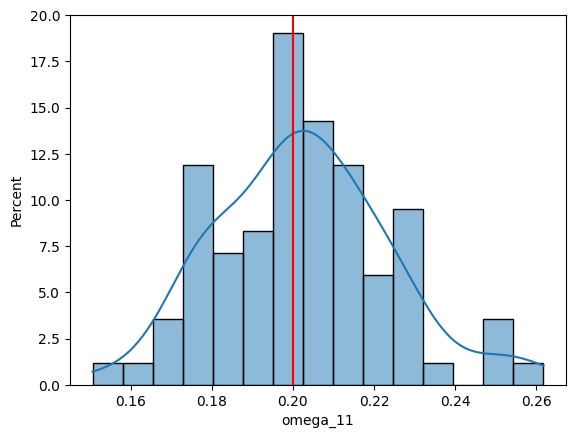

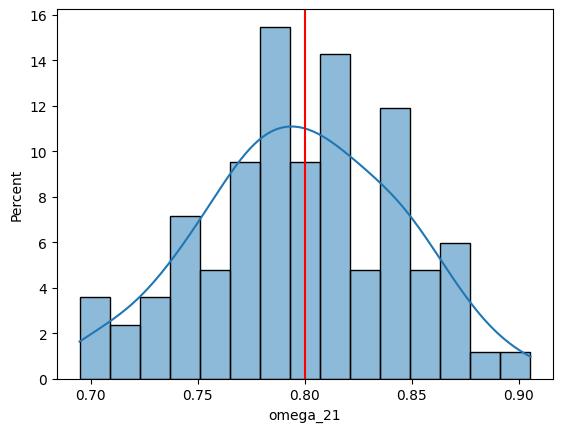

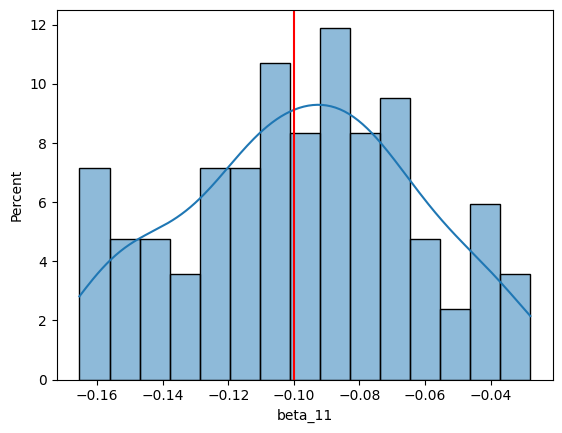

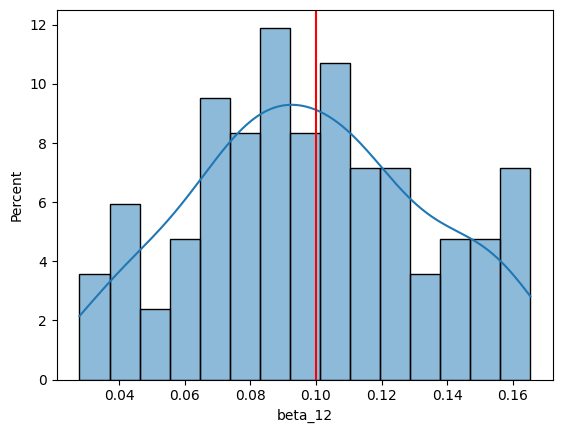

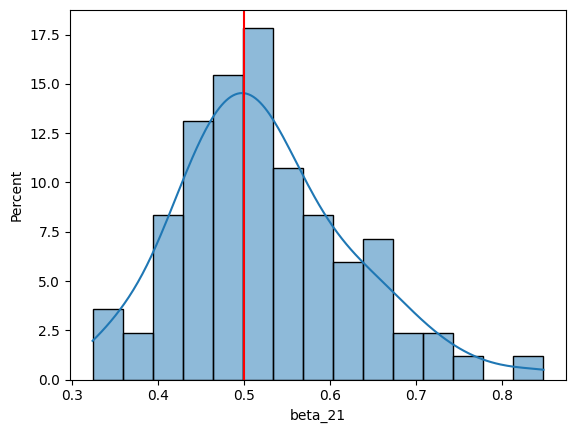

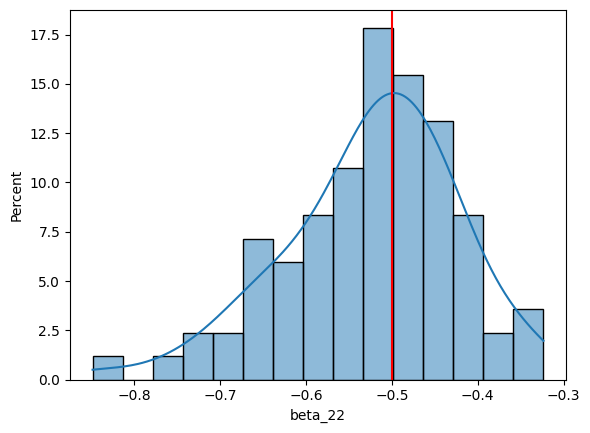

In [136]:
for col in true_values.columns:
    df[col+' error'] = true_values[col].squeeze() - df[col]
    sns.histplot(df.loc[299].dropna(axis=0),x=col,kde=True,stat='percent',bins=15)
    plt.axvline(true_values[col].squeeze(),color='red')
    plt.show()